In [1]:
import numpy as np
import csv
import pandas as pd
from bokeh.plotting import figure, output_notebook, show
from bokeh.models import HoverTool
from bokeh.io import output_file
from bokeh.models import ColumnDataSource, NumeralTickFormatter
from bokeh.layouts import layout
from bokeh.layouts import column
from bokeh.models import RangeSlider
from bokeh.models.widgets import Slider, TextInput

from scipy.signal import find_peaks
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import os
from pathlib import Path

In [2]:
SAVEDIR = Path(os.path.expanduser("~/ECM_mod_output/UMAP/"))
if not os.path.exists(SAVEDIR):
    os.mkdir(SAVEDIR)

In [3]:
#UMAP stochastic

embedding_prot_erl_7_7_1_1 = pd.read_csv(str(SAVEDIR) + '\\embedding_erl_4-9_1_1.csv',header=None)
embedding_prot_erl_7_7_2_1 = pd.read_csv(str(SAVEDIR) + '\\embedding_erl_4-9_2_1.csv',header=None)
embedding_prot_erl_7_7_3_1 = pd.read_csv(str(SAVEDIR) + '\\embedding_erl_4-9_3_1.csv',header=None)

#prot stochastic

all_prot_erl_7_7_1_1 = pd.read_csv(str(SAVEDIR) + '\\all_prot_erl_4-9_1_1.csv',header=None)
all_prot_erl_7_7_2_1 = pd.read_csv(str(SAVEDIR) + '\\all_prot_erl_4-9_2_1.csv',header=None)
all_prot_erl_7_7_3_1 = pd.read_csv(str(SAVEDIR) + '\\all_prot_erl_4-9_3_1.csv',header=None)

#UMAP stochastic

embedding_prot_dmso_7_7_1_1 = pd.read_csv(str(SAVEDIR) + '\\embedding_dmso_4-9_1_1.csv',header=None)
embedding_prot_dmso_7_7_2_1 = pd.read_csv(str(SAVEDIR) + '\\embedding_dmso_4-9_2_1.csv',header=None)
embedding_prot_dmso_7_7_3_1 = pd.read_csv(str(SAVEDIR) + '\\embedding_dmso_4-9_3_1.csv',header=None)
#prot stochastic

all_prot_dmso_7_7_1_1 = pd.read_csv(str(SAVEDIR) + '\\all_prot_dmso_4-9_1_1.csv',header=None)
all_prot_dmso_7_7_2_1 = pd.read_csv(str(SAVEDIR) + '\\all_prot_dmso_4-9_2_1.csv',header=None)
all_prot_dmso_7_7_3_1 = pd.read_csv(str(SAVEDIR) + '\\all_prot_dmso_4-9_3_1.csv',header=None)

#times

all_time_stoch = pd.read_csv(str(SAVEDIR) + '\\all_time_erl_4-9_1_1.csv',header=None)
all_time_at_stoch = pd.read_csv(str(SAVEDIR) + '\\all_time_at_erl_4-9_1_1.csv',header=None)

In [4]:
#UMAP stochastic

embedding_prot_p21_2 = pd.read_csv(str(SAVEDIR) + '\\embedding_prot_p21_2.csv',header=None)
embedding_prot_p21_4 = pd.read_csv(str(SAVEDIR) + '\\embedding_prot_p21_4.csv',header=None)
embedding_prot_V2Me_2 = pd.read_csv(str(SAVEDIR) + '\\embedding_prot_V2Me_2.csv',header=None)
embedding_prot_V2Me_4 = pd.read_csv(str(SAVEDIR) + '\\embedding_prot_V2Me_4.csv',header=None)

#prot stochastic

all_prot_p21_2 = pd.read_csv(str(SAVEDIR) + '\\all_prot_prot_p21_2.csv',header=None)
all_prot_p21_4 = pd.read_csv(str(SAVEDIR) + '\\all_prot_prot_p21_4.csv',header=None)
all_prot_V2Me_2 = pd.read_csv(str(SAVEDIR) + '\\all_prot_prot_V2Me_2.csv',header=None)
all_prot_V2Me_4 = pd.read_csv(str(SAVEDIR) + '\\all_prot_prot_V2Me_4.csv',header=None)

In [5]:
window_size = len(all_prot_erl_7_7_3_1.columns)/18
cyce=int((window_size*11+window_size/2)-1)
cdc20=int((window_size*17+window_size/2)-1)

In [6]:
def restructProt(protDF, embedDF, timeDF):
    peaks_E, _ = find_peaks(protDF[cyce], prominence = 40/200, distance = 10)
    peaks_cdc, _ = find_peaks(protDF[cdc20], prominence = 40/200, distance = 10)
    
    mit_win = pd.DataFrame()
    time_win = pd.DataFrame()
    umap_win = pd.DataFrame()
    
    for n in range(2,len(peaks_cdc)-3):   #make sure we have divisions at ends 
        tmp_mit = peaks_cdc[n]
        tmp_mit2 = peaks_cdc[n+1]
        tmp_mit3 = peaks_cdc[n+2]
        tmp_mit4 = peaks_cdc[n+3]
        
        tmp_g1_s = peaks_E[(tmp_mit < peaks_E) & (peaks_E < tmp_mit2)]
        tmp_g1_s_2 = peaks_E[(tmp_mit2 < peaks_E) & (peaks_E < tmp_mit3)]
        tmp_g1_s_3 = peaks_E[(tmp_mit3 < peaks_E) & (peaks_E < tmp_mit4)]    
             
        if (np.size(tmp_g1_s) > 0) & (np.size(tmp_g1_s_2)>0) & (np.size(tmp_g1_s_3)>0):
            ordered = [tmp_mit, tmp_g1_s[0], tmp_mit2, tmp_g1_s_2[0], tmp_mit3, tmp_g1_s_3[0], tmp_mit4]
            g1_len_tmp = np.array(timeDF.iloc[ordered[3],0]) - np.array(timeDF.iloc[[ordered[2]],0])
            tmp_prot = protDF.iloc[int(ordered[1]):int(ordered[3]),:]
            tmp_umap = embedDF.iloc[int(ordered[1]):int(ordered[3]),:]
            tmp_time = timeDF.iloc[int(ordered[1]):int(ordered[3]),:]
            tmp = [g1_len_tmp]*len(tmp_time)
            tmp = np.concatenate(tmp, axis=0)
            tmp_time.insert(1, 'G1', tmp)
            
            mit_win = pd.concat([mit_win,tmp_prot],ignore_index=True)
            time_win = pd.concat([time_win, tmp_time], ignore_index=True)
            umap_win = pd.concat([umap_win, tmp_umap], ignore_index=True)
            
    return mit_win, time_win, umap_win

In [9]:
mit_win_erl_1_1, time_win_erl_1_1, umap_win_erl_1_1 = restructProt(all_prot_erl_7_7_1_1, embedding_prot_erl_7_7_1_1, all_time_at_stoch)
mit_win_erl_2_1, time_win_erl_2_1, umap_win_erl_2_1 = restructProt(all_prot_erl_7_7_2_1, embedding_prot_erl_7_7_2_1, all_time_at_stoch)
mit_win_erl_3_1, time_win_erl_3_1, umap_win_erl_3_1 = restructProt(all_prot_erl_7_7_3_1, embedding_prot_erl_7_7_3_1, all_time_at_stoch)

mit_win_dmso_1_1, time_win_dmso_1_1, umap_win_dmso_1_1 = restructProt(all_prot_dmso_7_7_1_1, embedding_prot_dmso_7_7_1_1, all_time_at_stoch)
mit_win_dmso_2_1, time_win_dmso_2_1, umap_win_dmso_2_1 = restructProt(all_prot_dmso_7_7_2_1, embedding_prot_dmso_7_7_2_1, all_time_at_stoch)
mit_win_dmso_3_1, time_win_dmso_3_1, umap_win_dmso_3_1 = restructProt(all_prot_dmso_7_7_3_1, embedding_prot_dmso_7_7_3_1, all_time_at_stoch)

In [8]:
mit_win_p21_2, time_win_p21_2, umap_win_p21_2 = restructProt(all_prot_p21_2, embedding_prot_p21_2, all_time_at_stoch)
mit_win_p21_4, time_win_p21_4, umap_win_p21_4 = restructProt(all_prot_p21_4, embedding_prot_p21_4, all_time_at_stoch)

mit_win_V2Me_2, time_win_V2Me_2, umap_win_V2Me_2 = restructProt(all_prot_V2Me_2, embedding_prot_V2Me_2, all_time_at_stoch)
mit_win_V2Me_4, time_win_V2Me_4, umap_win_V2Me_4 = restructProt(all_prot_V2Me_4, embedding_prot_V2Me_4, all_time_at_stoch)


IndexError: index 25861 is out of bounds for axis 0 with size 24981

In [ ]:
# embedding_prot_erl_nop21 = pd.read_csv('embedding_erl_stoch_no_p21_4_25_2.csv',header=None)
# all_prot_erl_nop21 = pd.read_csv('all_prot_erl_stoch_no_p21_4_25_2.csv',header=None)
# mit_win_erl_nop21, time_win_erl_nop21, umap_win_erl_nop21 = restructProt(all_prot_erl_nop21, embedding_prot_erl_nop21, all_time_at_stoch)

In [ ]:
# umap_win_erl_1 = pd.concat([umap_win_erl_1_1,umap_win_erl_1_2,umap_win_erl_1_3],ignore_index=True)
# umap_win_erl_2 = pd.concat([umap_win_erl_2_1,umap_win_erl_2_2,umap_win_erl_2_3],ignore_index=True)
# umap_win_erl_3 = pd.concat([umap_win_erl_3_1,umap_win_erl_3_2,umap_win_erl_3_3],ignore_index=True)

# umap_win_dmso_1 = pd.concat([umap_win_dmso_1_1,umap_win_dmso_1_2,umap_win_dmso_1_3],ignore_index=True)
# umap_win_dmso_2 = pd.concat([umap_win_dmso_2_1,umap_win_dmso_2_2,umap_win_dmso_2_3],ignore_index=True)
# umap_win_dmso_3 = pd.concat([umap_win_dmso_3_1,umap_win_dmso_3_2,umap_win_dmso_3_3],ignore_index=True)

# mit_win_erl_1 = pd.concat([mit_win_erl_1_1,mit_win_erl_1_2,mit_win_erl_1_3],ignore_index=True)
# mit_win_erl_2 = pd.concat([mit_win_erl_2_1,mit_win_erl_2_2,mit_win_erl_2_3],ignore_index=True)
# mit_win_erl_3 = pd.concat([mit_win_erl_3_1,mit_win_erl_3_2,mit_win_erl_3_3],ignore_index=True)

# mit_win_dmso_1 = pd.concat([mit_win_dmso_1_1,mit_win_dmso_1_2,mit_win_dmso_1_3],ignore_index=True)
# mit_win_dmso_2 = pd.concat([mit_win_dmso_2_1,mit_win_dmso_2_2,mit_win_dmso_2_3],ignore_index=True)
# mit_win_dmso_3 = pd.concat([mit_win_dmso_3_1,mit_win_dmso_3_2,mit_win_dmso_3_3],ignore_index=True)

In [10]:
y_label_list = ['Skp2', 'p21', 'pp21', 'Cdh1', 'Myc', 'CycD', 'CycDp21', 'Rb', 'pRb', 'E2F', 'RbE2F',
                'CycE', 'CycEp21', 'CycA', 'CycAp21', 'CycB', 'CycBp21', 'Cdc20']

Text(0.5, 1.0, 'Rb')

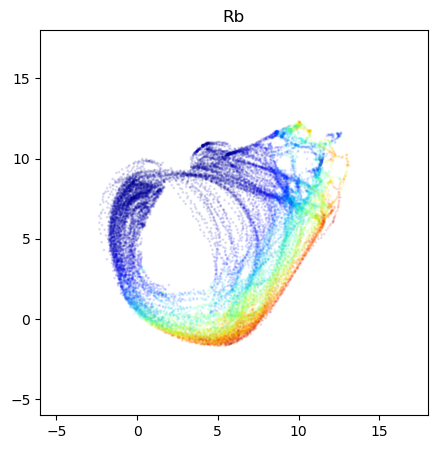

In [12]:
xmin, xmax = -6, 18
ymin, ymax = -6, 18
n=7

fig = plt.figure()
ax = fig.gca()
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
fig.set_size_inches(5, 5)
plt.scatter(umap_win_erl_2_1[0],umap_win_erl_2_1[1],c=mit_win_erl_2_1[int((window_size*n+window_size/2)-1)],s=1,cmap='jet',
           alpha=0.1)
plt.clim(0, 1)
plt.title(y_label_list[n])

#labels = [item.get_text() for item in ax.get_xticklabels()]
#labels = ['-10', '-5', '0', '5', '10', '15']
#ax.set_xticklabels(labels)

In [ ]:
xmin, xmax = -6, 18
ymin, ymax = -6, 18
n=11

fig = plt.figure()
ax = fig.gca()
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
fig.set_size_inches(5, 5)
plt.scatter(umap_win_erl_2_1[0],umap_win_erl_2_1[1],c=mit_win_erl_2_1[int((window_size*n+window_size/2)-1)],s=1,cmap='jet',
           alpha=0.1)
plt.clim(0, 1)
plt.title(y_label_list[n])

#labels = [item.get_text() for item in ax.get_xticklabels()]
#labels = ['-10', '-5', '0', '5', '10', '15']
#ax.set_xticklabels(labels)

In [ ]:
xmin, xmax = -6, 18
ymin, ymax = -6, 18
n=5

fig = plt.figure()
ax = fig.gca()
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
fig.set_size_inches(5, 5)
plt.scatter(umap_win_erl_2_1[0],umap_win_erl_2_1[1],c=mit_win_erl_2_1[int((window_size*n+window_size/2)-1)],s=1,cmap='jet',
           alpha=0.1)
plt.clim(0, 1)
plt.title(y_label_list[n])

In [ ]:
xmin, xmax = -6, 18
ymin, ymax = -6, 18
n=9

fig = plt.figure()
ax = fig.gca()
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
fig.set_size_inches(5, 5)
plt.scatter(umap_win_erl_2_1[0],umap_win_erl_2_1[1],c=mit_win_erl_2_1[int((window_size*n+window_size/2)-1)],s=1,cmap='jet',
           alpha=0.1)
plt.clim(0, 1)
plt.title(y_label_list[n])

In [ ]:
xmin, xmax = -6, 18
ymin, ymax = -6, 18
n=10

fig = plt.figure()
ax = fig.gca()
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
fig.set_size_inches(5, 5)
plt.scatter(umap_win_erl_2_1[0],umap_win_erl_2_1[1],c=mit_win_erl_2_1[int((window_size*n+window_size/2)-1)],s=1,cmap='jet',
           alpha=0.1)
plt.clim(0, 1)
plt.title(y_label_list[n])

In [ ]:
xmin, xmax = -6, 18
ymin, ymax = -6, 18
n=13

fig = plt.figure()
ax = fig.gca()
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
fig.set_size_inches(5, 5)
plt.scatter(umap_win_erl_2_1[0],umap_win_erl_2_1[1],c=mit_win_erl_2_1[int((window_size*n+window_size/2)-1)],s=1,cmap='jet',
           alpha=0.1)
plt.clim(0, 1)
plt.title(y_label_list[n])

In [ ]:
xmin, xmax = -6, 18
ymin, ymax = -6, 18
n=4

fig = plt.figure()
ax = fig.gca()
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
fig.set_size_inches(5, 5)
plt.scatter(umap_win_erl_2_1[0],umap_win_erl_2_1[1],c=mit_win_erl_2_1[int((window_size*n+window_size/2)-1)],s=1,cmap='jet',
           alpha=0.1)
plt.clim(0.3, 0.8)
plt.title(y_label_list[n])

#labels = [item.get_text() for item in ax.get_xticklabels()]
#labels = ['-10', '-5', '0', '5', '10', '15']
#ax.set_xticklabels(labels)

In [ ]:
xmin, xmax = -6, 18
ymin, ymax = -6, 18
n=13

fig = plt.figure()
ax = fig.gca()
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
fig.set_size_inches(5, 5)
plt.scatter(umap_win_dmso_3_1[0],umap_win_dmso_3_1[1],c=mit_win_dmso_3_1[int((window_size*n+window_size/2)-1)],s=1,cmap='jet',
           alpha=0.1)
plt.clim(0, 1)
plt.title(y_label_list[n])

In [ ]:
xmin, xmax = -18, 6
ymin, ymax = -6, 18
n=7

fig = plt.figure()
ax = fig.gca()
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
fig.set_size_inches(5, 5)
plt.scatter(-umap_win_V2Me_4[1],umap_win_V2Me_4[0],c=mit_win_V2Me_4[int((window_size*n+window_size/2)-1)],s=1,cmap='jet',
           alpha=0.1)
plt.clim(0, 1)

In [ ]:
xmin, xmax = -18, 6
ymin, ymax = -6, 18
n=11

fig = plt.figure()
ax = fig.gca()
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
fig.set_size_inches(5, 5)
plt.scatter(-umap_win_V2Me_2[1],umap_win_V2Me_2[0],c=mit_win_V2Me_2[int((window_size*n+window_size/2)-1)],s=1,cmap='jet',
           alpha=0.1)
plt.clim(0, 1)

In [ ]:
fig = plt.figure()
ax = fig.gca()
ax.set_xlim(5000, 10000)
n=11
plt.plot(mit_win_V2Me_2[int((window_size*n+window_size/2)-1)])
n=17
plt.plot(mit_win_V2Me_2[int((window_size*n+window_size/2)-1)])

In [ ]:
plt.figure(figsize=(15,30))
plt.subplots_adjust(hspace=0.5)
xmin, xmax = -6, 18
ymin, ymax = -6, 18

for n, name in enumerate(y_label_list):
    ax = plt.subplot(6,3,n+1)
    plt.scatter(umap_win_V2Me_2[0],umap_win_V2Me_2[1],c=mit_win_V2Me_2[int((window_size*n+window_size/2)-1)],s=1,cmap='jet',
           alpha=0.1)
    ax.set_title(y_label_list[n])
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    plt.clim(0, 1)

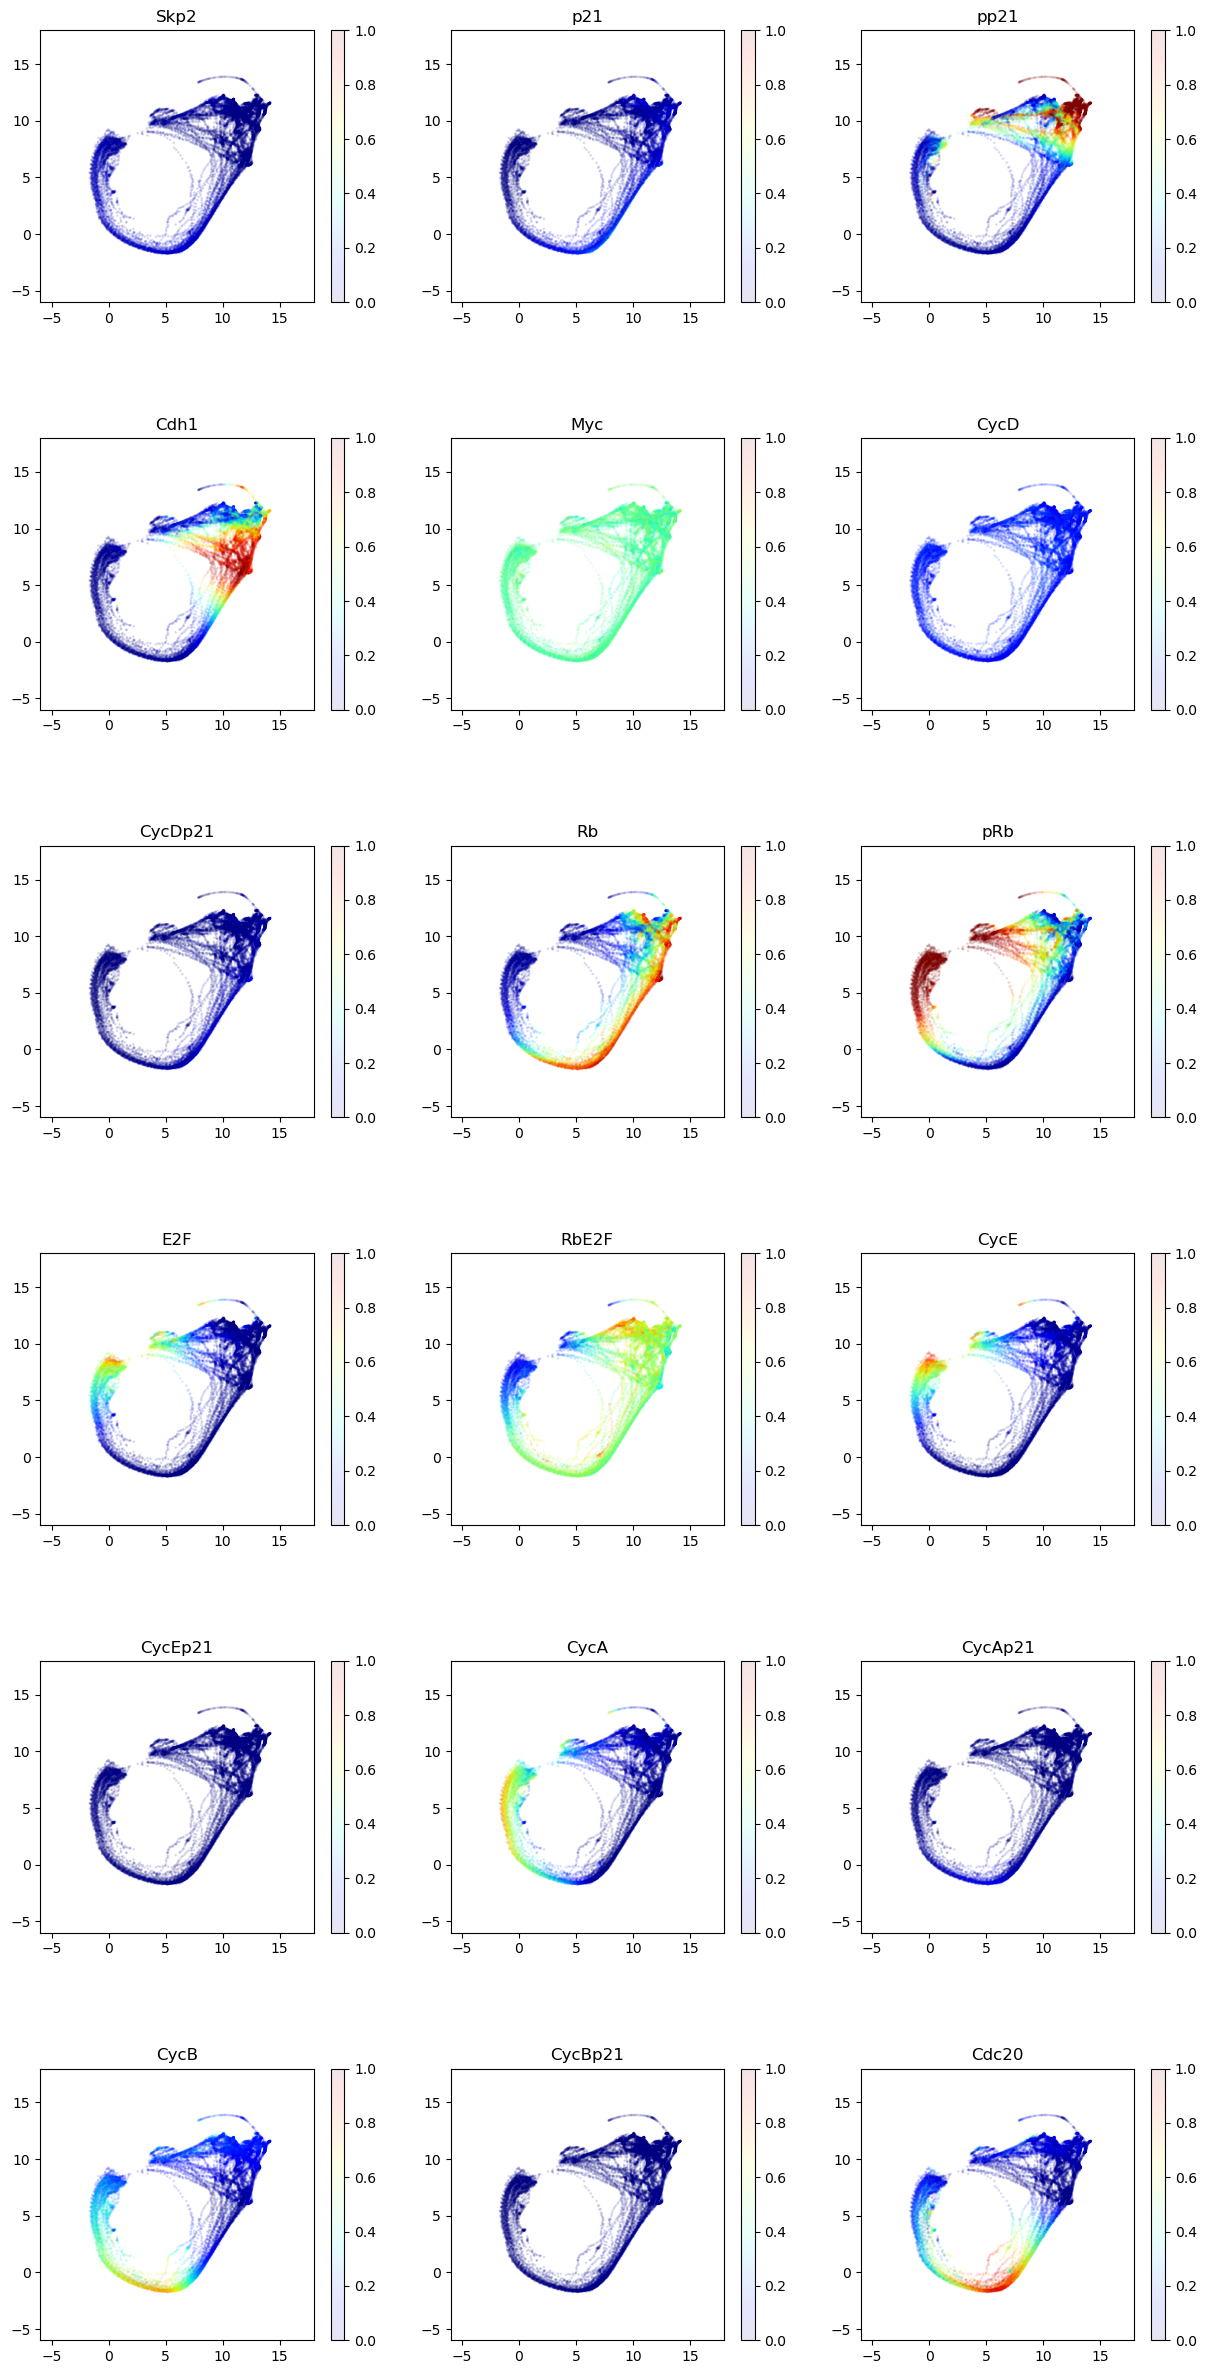

In [14]:
%matplotlib inline
plt.figure(figsize=(15,30))
plt.subplots_adjust(hspace=0.5)

for n, name in enumerate(y_label_list):
    ax = plt.subplot(6,3,n+1)
    plt.scatter(umap_win_erl_1_1[0],umap_win_erl_1_1[1],c=mit_win_erl_1_1[int((window_size*n+window_size/2)-1)],s=1,cmap='jet',
           alpha=0.1)
    #plt.scatter(umap_win_erl_1_1[0],umap_win_erl_1_1[1],c=mit_win_erl_1_1[n*50+24],s=3,cmap='jet')
    ax.set_title(y_label_list[n])
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    plt.clim(0, 1)
    plt.colorbar()
    
    

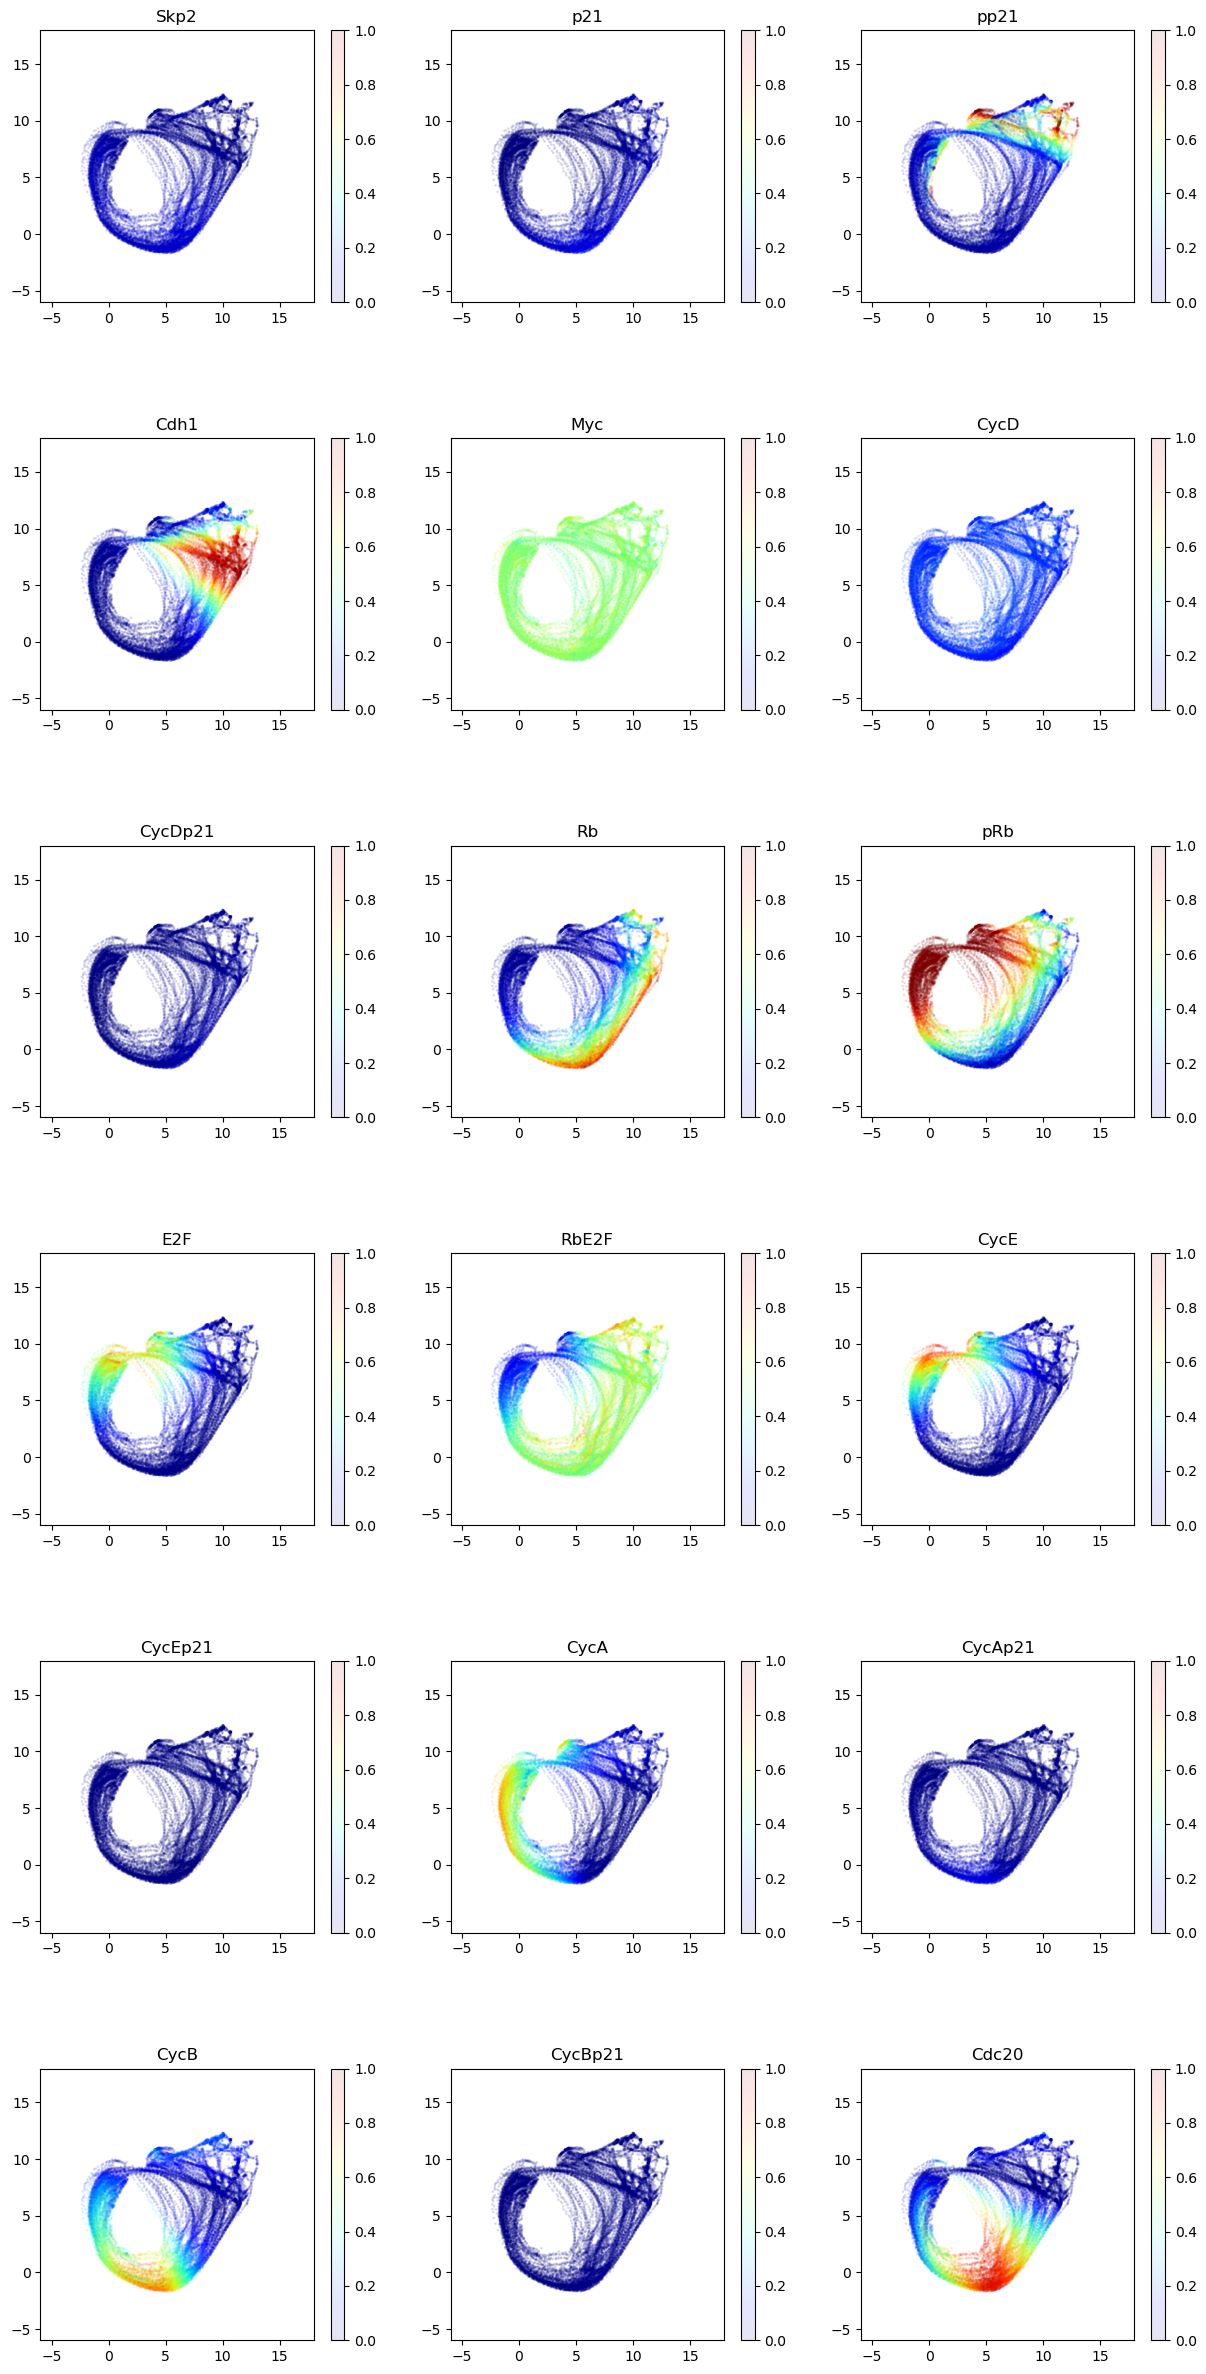

In [15]:
%matplotlib inline
plt.figure(figsize=(15,30))
plt.subplots_adjust(hspace=0.5)

for n, name in enumerate(y_label_list):
    ax = plt.subplot(6,3,n+1)
    plt.scatter(umap_win_erl_2_1[0],umap_win_erl_2_1[1],c=mit_win_erl_2_1[int((window_size*n+window_size/2)-1)],s=1,cmap='jet',
           alpha=0.1)
    #plt.scatter(umap_win_erl_1_1[0],umap_win_erl_1_1[1],c=mit_win_erl_1_1[n*50+24],s=3,cmap='jet')
    ax.set_title(y_label_list[n])
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    plt.clim(0, 1)
    plt.colorbar()
    
    

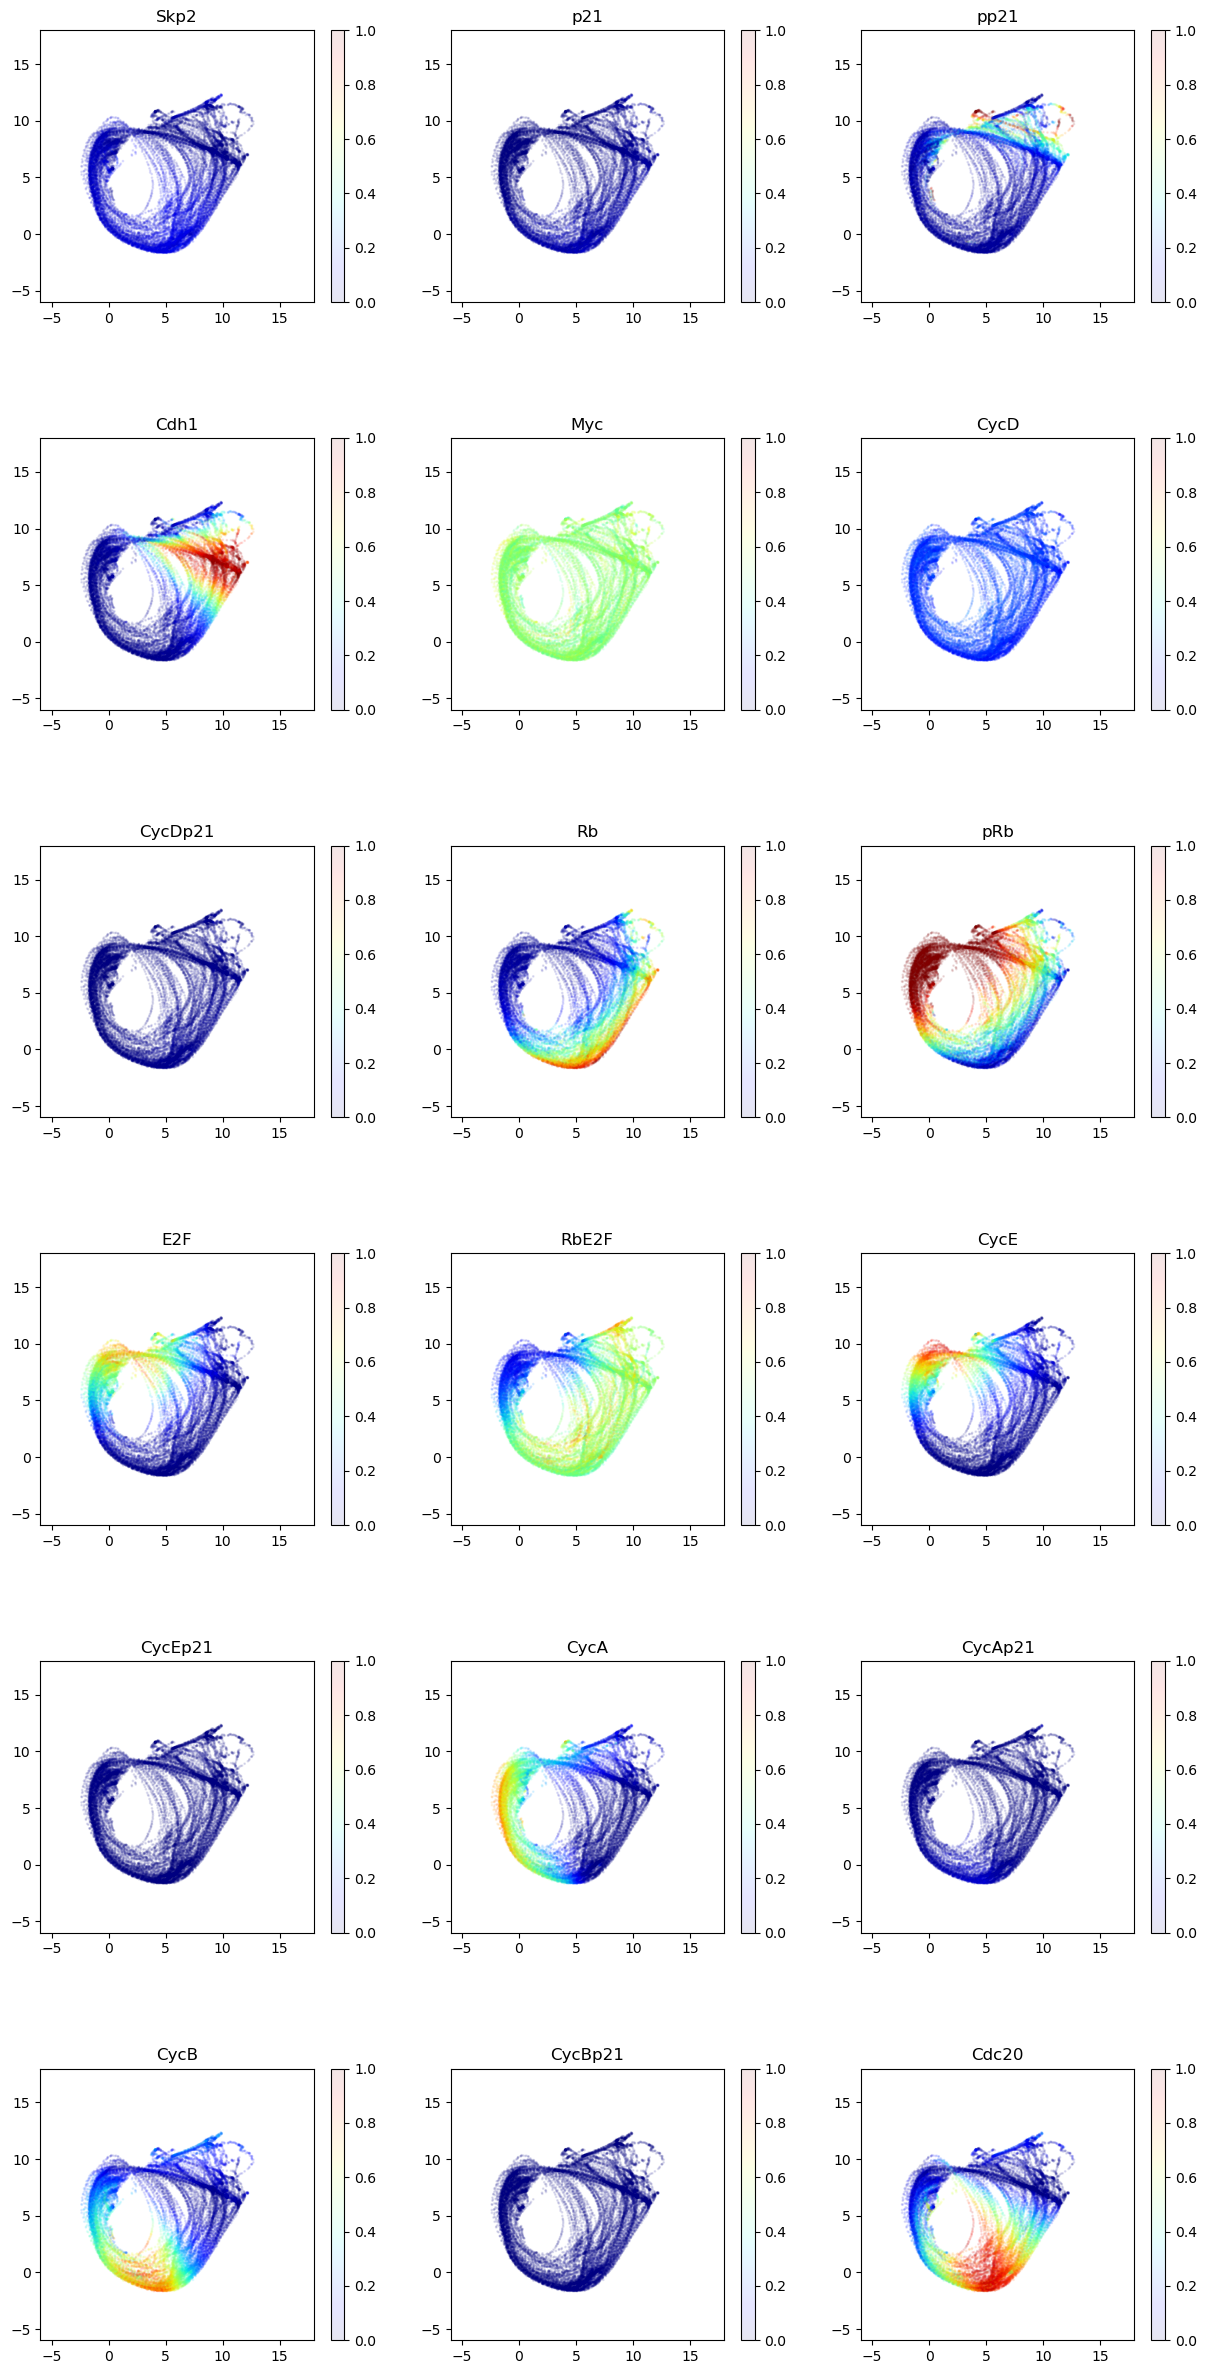

In [16]:
%matplotlib inline
plt.figure(figsize=(15,30))
plt.subplots_adjust(hspace=0.5)

for n, name in enumerate(y_label_list):
    ax = plt.subplot(6,3,n+1)
    plt.scatter(umap_win_erl_3_1[0],umap_win_erl_3_1[1],c=mit_win_erl_3_1[int((window_size*n+window_size/2)-1)],s=1,cmap='jet',
           alpha=0.1)
    #plt.scatter(umap_win_erl_1_1[0],umap_win_erl_1_1[1],c=mit_win_erl_1_1[n*50+24],s=3,cmap='jet')
    ax.set_title(y_label_list[n])
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    plt.clim(0, 1)
    plt.colorbar()
    
    

In [ ]:
plt.figure(figsize=(15,30))
plt.subplots_adjust(hspace=0.5)

for n, name in enumerate(y_label_list):
    ax = plt.subplot(6,3,n+1)
    plt.scatter(umap_win_dmso_1[0],umap_win_dmso_1[1],c=mit_win_dmso_1[n*50+24],s=3,norm=LogNorm(),cmap='jet')
    ax.set_title(y_label_list[n])
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    plt.clim(0.01, 1)

In [ ]:
plt.figure(figsize=(15,30))
plt.subplots_adjust(hspace=0.5)

for n, name in enumerate(y_label_list):
    ax = plt.subplot(6,3,n+1)
    plt.scatter(umap_win_dmso_2[0],umap_win_dmso_2[1],c=mit_win_dmso_2[n*50+24],s=3,norm=LogNorm(),cmap='jet')
    ax.set_title(y_label_list[n])
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    plt.clim(0.01, 1)

In [ ]:
plt.figure(figsize=(15,30))
plt.subplots_adjust(hspace=0.5)

for n, name in enumerate(y_label_list):
    ax = plt.subplot(6,3,n+1)
    plt.scatter(umap_win_dmso_3[0],umap_win_dmso_3[1],c=mit_win_dmso_3[n*50+24],s=3,norm=LogNorm(),cmap='jet')
    ax.set_title(y_label_list[n])
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    plt.clim(0.01, 1)

In [ ]:
plt.figure(figsize=(15,30))
plt.subplots_adjust(hspace=0.5)

for n, name in enumerate(y_label_list):
    ax = plt.subplot(6,3,n+1)
    plt.scatter(umap_win_erl_nop21[0],umap_win_erl_nop21[1],c=mit_win_erl_nop21[n*50+24],s=3,cmap='jet')
    ax.set_title(y_label_list[n])
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    plt.clim(0, 1)
    plt.colorbar()
    